# Percepción de inseguridad y victimización en Chile (ENUSC 2023)

## Entrega 4: Documento final

Análisis final: percepción del aumento de la delincuencia a nivel país, comuna y barrio; victimización y denuncia por tipo de delito; influencia de las fuentes de información y del nivel socioeconómico; brecha entre percepción y victimización, y efecto del temor en la vida cotidiana.

## **Análisis Exploratorio de los Datos**

### 1) Carga del Dataset

*Importacion de bibliotecas:*

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

*Lectura de la base de datos:*

In [87]:
df_enusc = pd.read_csv("../datos/base-usuario-20-enusc-2023.csv")

### 2) Vista general del Dataset

*Numero de filas y columnas (registros y variables) del Dataset:*

In [88]:
df_enusc.shape 

(146294, 1301)

*Resumen general del Dataset:*

In [89]:
df_enusc.info

<bound method DataFrame.info of                rph_ID         idhogar  enc_idr  enc_region  enc_rpc  com102  \
0       00-00-33-94_1  00-00-33-94-H1     7479          10    10101       1   
1       00-00-33-94_2  00-00-33-94-H1     7479          10    10101       1   
2       00-00-33-94_3  00-00-33-94-H1     7479          10    10101       1   
3       00-00-33-94_4  00-00-33-94-H1     7479          10    10101       1   
4       00-00-41-76_1  00-00-41-76-H1    46130          10    10202       1   
...               ...             ...      ...         ...      ...     ...   
146289  99-99-38-43_3  99-99-38-43-H1    39665           8     8201       0   
146290  99-99-38-43_4  99-99-38-43-H1    39665           8     8201       0   
146291  99-99-88-78_1  99-99-88-78-H1    20879           5     5109       1   
146292  99-99-88-78_2  99-99-88-78-H1    20879           5     5109       1   
146293  99-99-88-78_3  99-99-88-78-H1    20879           5     5109       1   

        IH_residenc

*Muestra de las primeras 5 columnas:*

In [90]:
df_enusc.head(5)

,rph_ID,idhogar,enc_idr,enc_region,enc_rpc,com102,IH_residencia_habitual,IH_comparte_gastos,IH_numero_grupos,IH_cantidad_hogar,...,EXT_LOCAL,SOB_LOCAL,Fact_Pers_Com,Fact_Pers_Reg,Fact_Pers_Regional_102,Fact_Hog_Com,Fact_Hog_Reg,Fact_Hog_Regional_102,VarStrat,Conglomerado
0,00-00-33-94_1,00-00-33-94-H1,7479,10,10101,1,4,1.0,NaN,1,...,0.0,0.0,425.245263,519.894835,591.228012,155.960818,192.60032,221.462682,20240101.0,2.023004e+09
1,00-00-33-94_2,00-00-33-94-H1,7479,10,10101,1,4,1.0,NaN,1,...,NaN,NaN,NaN,NaN,591.228012,NaN,NaN,221.462682,NaN,NaN
2,00-00-33-94_3,00-00-33-94-H1,7479,10,10101,1,4,1.0,NaN,1,...,NaN,NaN,NaN,NaN,591.228012,NaN,NaN,221.462682,NaN,NaN
3,00-00-33-94_4,00-00-33-94-H1,7479,10,10101,1,4,1.0,NaN,1,...,NaN,NaN,NaN,NaN,591.228012,NaN,NaN,221.462682,NaN,NaN
4,00-00-41-76_1,00-00-41-76-H1,46130,10,10202,1,4,1.0,NaN,1,...,NaN,NaN,NaN,NaN,222.646726,NaN,NaN,64.841374,NaN,NaN


### 3) Analisis general de variables

* Tipo de datos de las variables del Dataset:*

In [91]:
df_enusc.dtypes

rph_ID                    object
idhogar                   object
enc_idr                    int64
enc_region                 int64
enc_rpc                    int64
                          ...   
Fact_Hog_Com             float64
Fact_Hog_Reg             float64
Fact_Hog_Regional_102    float64
VarStrat                 float64
Conglomerado             float64
Length: 1301, dtype: object

*Frecuencia de los tipo de datos:*

In [92]:
df_enusc.dtypes.value_counts()

float64    1286
int64        13
object        2
Name: count, dtype: int64

*Muestra de la frecuencia de los valores de las variables:*

In [93]:
cant_nulos_variables=df_enusc.isna().mean().sort_values(ascending=False)
cant_nulos_variables.head(1000) 

EST_QUIEN__3             0.999993
RPS_QUIEN__3             0.999993
AGR_QUIEN__3             0.999993
AGR_QUIEN__4             0.999993
SOB_DONDE_REGION         0.999993
                           ...   
RDDV_MED_SEGURIDAD__7    0.976123
RDDV_DONDE_OCURRIO       0.976123
RDDV_DENUNCIAS           0.976123
RDDV_MED_SEGURIDAD__2    0.976123
RDDV_REGION              0.976123
Length: 1000, dtype: float64

Podemos ver que una gran cantidad de variables, en este 1000 variables del total 1301 variables, tienen una frecuencia de datos nulos sobre el 97%, esto es debido a que muchas de las preguntas estan condicionadas a respuestas anteriores, por ejemplo,  si la persona "fue victima de un delito especifico", "realizo una denuncia", etc.



### 4) Analisis Exploratorio de los datos:

#### 4.1) Percepcion del Aumento inseguridad

*Percepcion del Aumento inseguridad nivel `Pais`,`Comuna` y `Barrio` agrupado por Region*

In [94]:
reg_labels = {
    1: "Tarapacá", 2: "Antofagasta", 3: "Atacama", 4: "Coquimbo", 5: "Valparaíso",
    6: "O'Higgins", 7: "Maule", 8: "Biobío", 9: "La Araucanía", 10: "Los Lagos",
    11: "Aysén", 12: "Magallanes", 13: "Metropolitana", 14: "Los Ríos",
    15: "Arica y Parinacota", 16: "Ñuble"
}

etiquetas_percepcion = {
    1: "Aumentó",
    2: "No Aumentó",
    3: "Disminuyó",
    88: "No sabe",
    99: "No responde"
}

orden_regiones = [
    "Arica y Parinacota", "Tarapacá", "Antofagasta", "Atacama", "Coquimbo",
    "Valparaíso", "Metropolitana", "O'Higgins", "Maule", "Ñuble",
    "Biobío", "La Araucanía", "Los Ríos", "Los Lagos", "Aysén", "Magallanes"
]

orden_columnas = ["Aumentó", "No Aumentó", "Disminuyó"]

In [95]:
def graficar_percepcion_por_region(df, columna, titulo):
    df_region = df[["enc_region", columna]].copy()
    df_region[columna] = df_region[columna].replace([88, 99], pd.NA)
    df_region = df_region.dropna()

    df_region[columna] = df_region[columna].replace(etiquetas_percepcion)
    df_region["enc_region"] = df_region["enc_region"].replace(reg_labels)

    tabla = pd.crosstab(
        df_region["enc_region"],
        df_region[columna],
        normalize='index'
    ) * 100

    # Asegurar orden
    for col in orden_columnas:
        if col not in tabla.columns:
            tabla[col] = 0

    tabla = tabla[orden_columnas].loc[orden_regiones]
    tabla = tabla.round(2)

    # Media
    media_grafico = tabla["Aumentó"].mean()


    ax = tabla.plot(kind='bar', stacked=True, figsize=(14, 8), colormap="Set2")

    plt.axhline(media_grafico, color='red', linestyle='--',
                label=f"Estimación Nacional ({columna.lower()}): {media_grafico:.2f}%")
    
    plt.title(titulo)
    plt.xlabel("Región")
    plt.ylabel("Porcentaje")
    plt.xticks(rotation=45, ha='right')
    plt.legend(title="Percepción", loc='upper right')
    plt.tight_layout()
    plt.show()


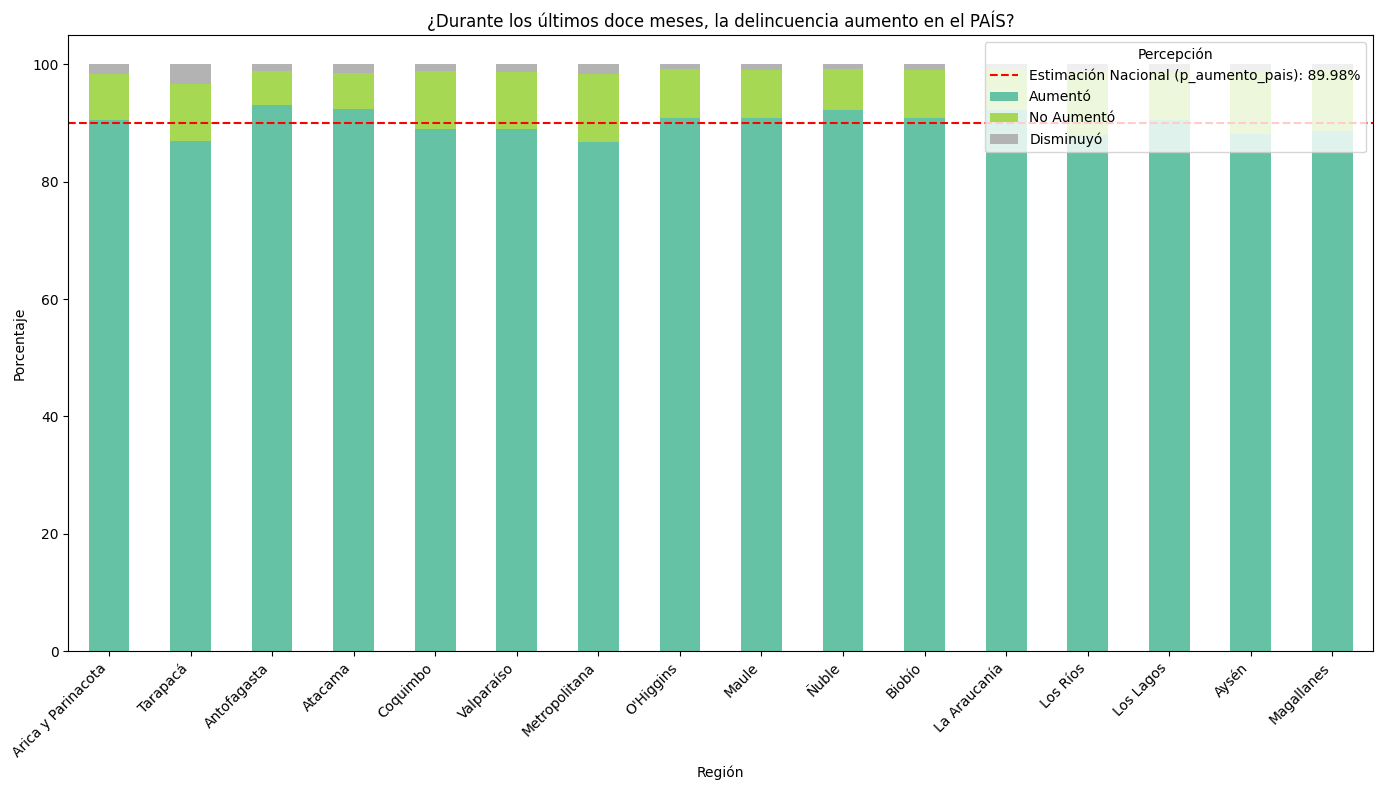

In [96]:
# País
graficar_percepcion_por_region(
    df_enusc,
    "P_AUMENTO_PAIS",
    "¿Durante los últimos doce meses, la delincuencia aumento en el PAÍS?"
)


Podemos apreciar que la percepcion de que la delincuencia aumento en el pais es alta en todas las regiones, con una media del 89.98% que consideran que aumento, lo que podriamos considerar preocupante.

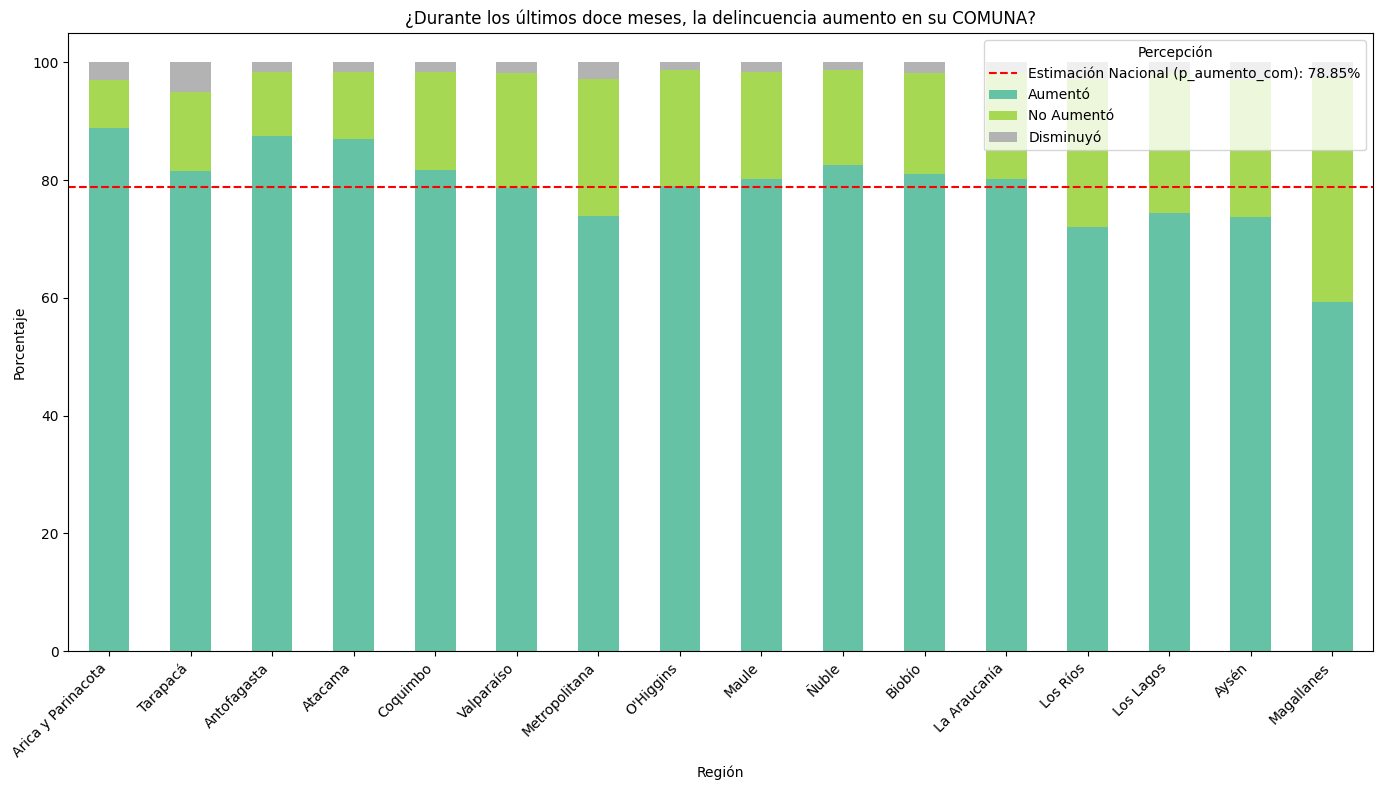

In [97]:
# Comuna
graficar_percepcion_por_region(
    df_enusc,
    "P_AUMENTO_COM",
    "¿Durante los últimos doce meses, la delincuencia aumento en su COMUNA?"
)

Podemos apreciar que la percepcion de que la delincuencia en la comuna de los entrevistados es relativamente alta en casi todas las regiones, pero podemos apreciar algo llamativo que parece ser que a medida que nos acercanos mas al sur parece que tiene una tendencia a disminiur la percepcion.
Ademas es bueno recalcar que se obtuvo una percepcion mas baja que a nivel pais, asi obteniendo alrededor de un 11% menos, con un 78.85% de que Aumento la delicuencia, lo que podriamos concluir que mucha gente considere que el pais es inseguro pero tenga una mejor imagen de su comuna.

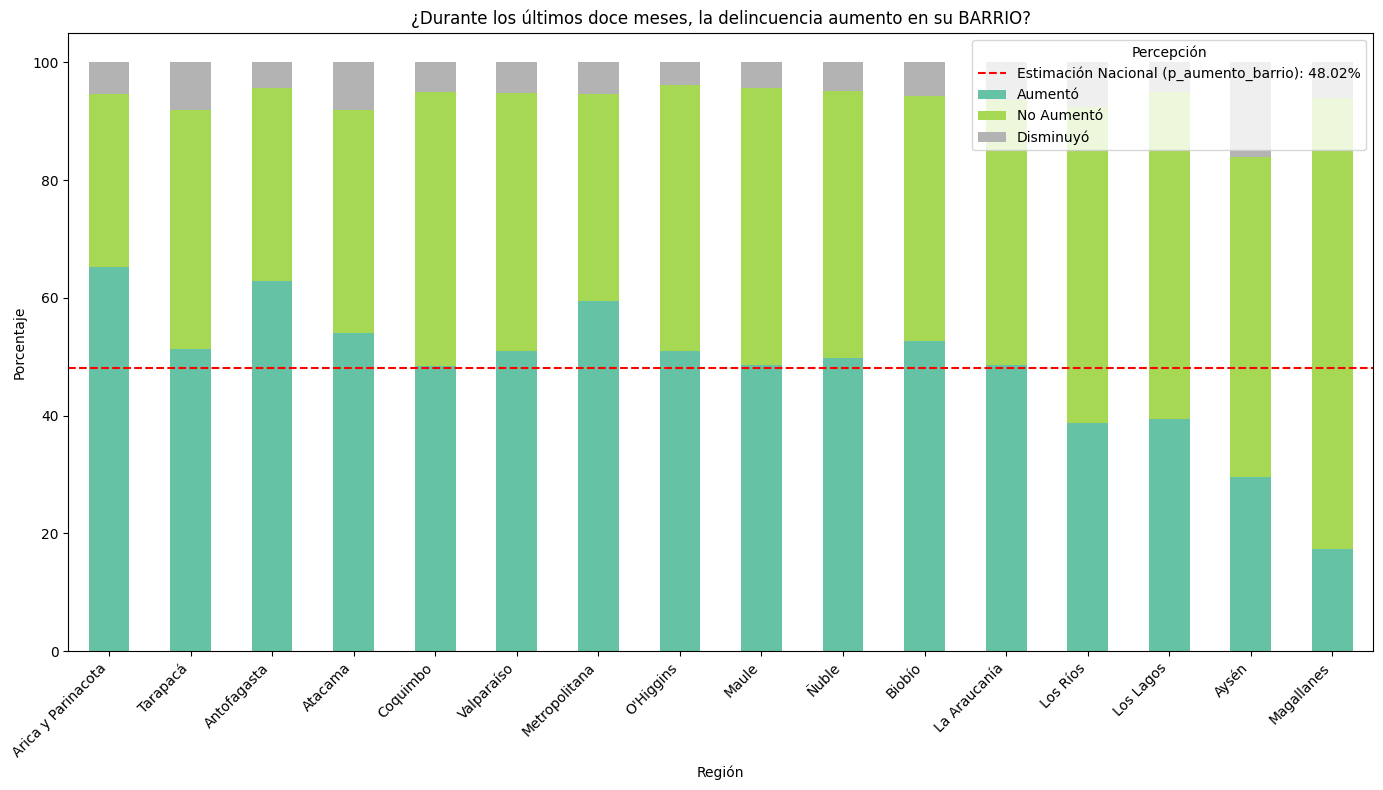

In [98]:
# Barrio
graficar_percepcion_por_region(
    df_enusc,
    "P_AUMENTO_BARRIO",
    "¿Durante los últimos doce meses, la delincuencia aumento en su BARRIO?"
)

Ahora para la percepcion de inseguridad en el barrio de los entrevistados, podemos apreciar que vario en gran medida a comparacion de las anteriores graficas, se obtuvo una estimacion nacional de 48.02% alrededor de un 41% de diferencia con el nivel comunal y un 52% aproximadamente con respecto al pais, esto lo podemos concluir que se debe a que muchas personas se puedan sentir mas seguras en sus barrios, pues es un ambiente donde pasan una gran parte de su vida.
Ademas podemos apreciar que la tendencia del grafico anterior de que se va reduciendo la percepcion de inseguridad a medida que nos acercamos al sur de Chile parece mantenerse.

> **Nota (revisión posterior):** la diferencia es de unos 31 puntos porcentuales respecto del nivel comunal (78,85 %) y de unos 42 puntos respecto del país (89,98 %).

*Percepcion del aumento de inseguridad con respecto a la edad*

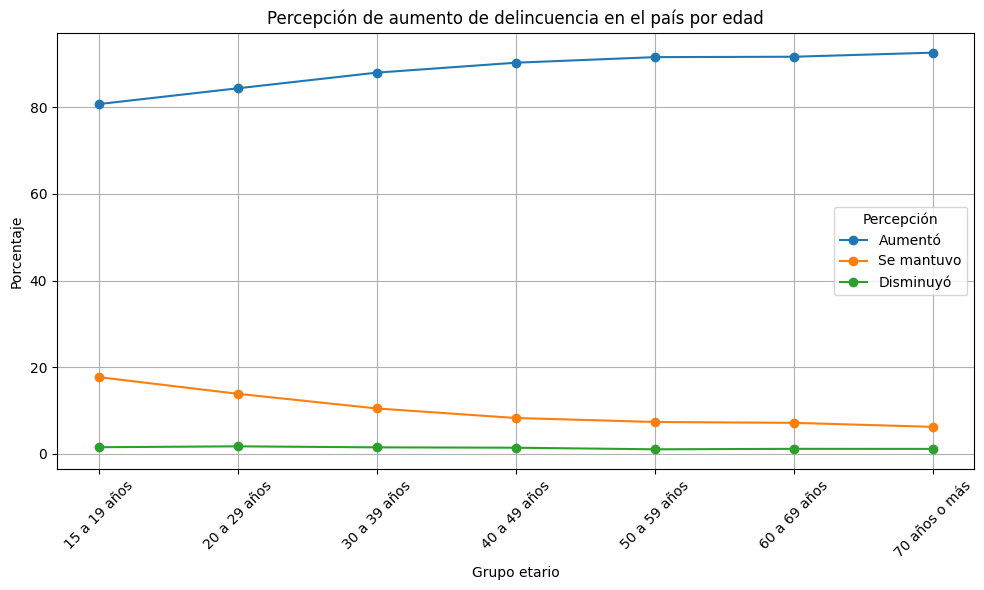

In [99]:
df_pais = df_enusc[["rph_edad", "P_AUMENTO_PAIS"]].copy()

df_pais = df_pais[df_pais["P_AUMENTO_PAIS"].isin([1, 2, 3])]

labels_edad = {
    0: "0 a 14 años",
    1: "15 a 19 años",
    2: "20 a 29 años",
    3: "30 a 39 años",
    4: "40 a 49 años",
    5: "50 a 59 años",
    6: "60 a 69 años",
    7: "70 años o más"
}
df_pais["rph_edad"] = df_pais["rph_edad"].replace(labels_edad)

percepcion_labels = {
    1: "Aumentó",
    2: "Se mantuvo",
    3: "Disminuyó"
}
df_pais["P_AUMENTO_PAIS"] = df_pais["P_AUMENTO_PAIS"].replace(percepcion_labels)

#tabla cruzada normalizada
tabla = pd.crosstab(
    df_pais["rph_edad"],
    df_pais["P_AUMENTO_PAIS"],
    normalize='index'
) * 100

orden_columnas = ["Aumentó", "Se mantuvo", "Disminuyó"]
tabla = tabla[orden_columnas]

plt.figure(figsize=(10, 6))
for col in tabla.columns:
    plt.plot(tabla.index, tabla[col], marker='o', label=col)

plt.title("Percepción de aumento de delincuencia en el país por edad")
plt.xlabel("Grupo etario")
plt.ylabel("Porcentaje")
plt.xticks(rotation=45)
plt.legend(title="Percepción")
plt.grid(True)
plt.tight_layout()
plt.show()

Podemos apreciar una tendencia clara, de que a medida que las personas envejecen consideran que la percepcion de inseguridad aumento, puede ser debido a que al envejecer muchas personas pueden sentirse mal vunerables al ver o sentir sus habilidades psicomotoros afectadas por los años.

 ### 4.2) Victimizacion
 

C:\Users\mario\AppData\Local\Temp\ipykernel_16036\1675464951.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=frecuencia.values, y=frecuencia.index, palette="Reds_r")


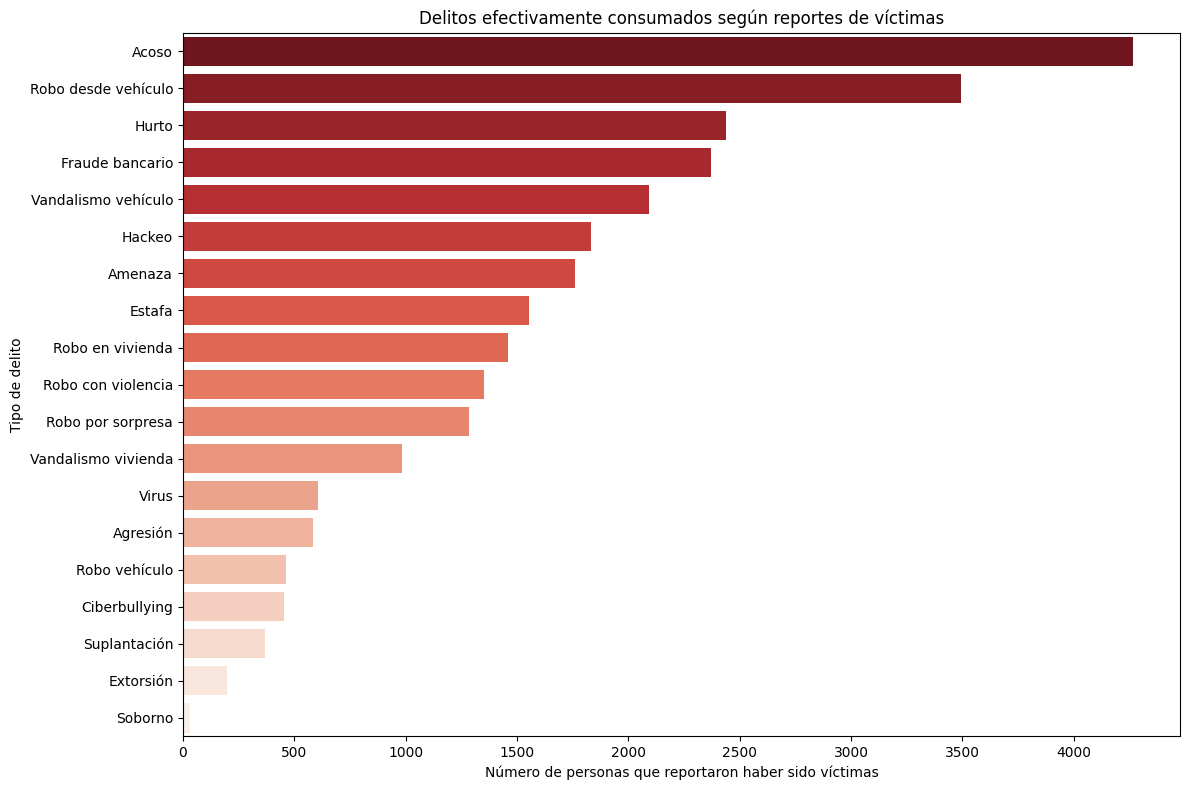

In [100]:
delitos_consumados = [
    "RDV", "RDDV", "RFV", "VANDVHC", "VANDVIV", "RVI", "RPS",
    "HUR", "FRB", "EST", "AGR", "AMEN", "EXT", "SOB", "HACK",
    "VIRUS", "BULLY", "SUPLANT", "VP_ACO"
]

nombres_delitos = [
    "Robo vehículo", "Robo desde vehículo", "Robo en vivienda", "Vandalismo vehículo", "Vandalismo vivienda",
    "Robo con violencia", "Robo por sorpresa", "Hurto", "Fraude bancario", "Estafa",
    "Agresión", "Amenaza", "Extorsión", "Soborno", "Hackeo",
    "Virus", "Ciberbullying", "Suplantación", "Acoso"
]

frecuencia = df_enusc[delitos_consumados].apply(lambda x: (x == 1).sum())
frecuencia.index = nombres_delitos

frecuencia = frecuencia.sort_values(ascending=False)


plt.figure(figsize=(12, 8))
sns.barplot(x=frecuencia.values, y=frecuencia.index, palette="Reds_r")
plt.title("Delitos efectivamente consumados según reportes de víctimas")
plt.xlabel("Número de personas que reportaron haber sido víctimas")
plt.ylabel("Tipo de delito")
plt.tight_layout()
plt.show()

Podemos ver que el Acoso es el delito más reportado, superando los 4.000 casos, lo que nos sugiere una alta prevalencia de violencia interpersonal, especialmente en espacios publicos.

Le siguen delitos contra la propiedad como robo desde vehículo, hurto, lo que podria reflejar vulnerabilidades en el espacio publico o incluso en el residencial.

Tambien se aprecia un crecimiento en delitos digitales como fraude bancario o hackeo, quizas debido a que la sociedad cada vez se vuelve mas digital.

Los delitos violentos aparecen con menor frecuencia, pero su impacto puede ser mayor en la victima asi que tambien es importante considerarlos.

Soborno y extorsion, podemos ver que son los que menos se reportan, esto podria ser por temor a denunciar o por su ocurrencia en entornos más complejos.

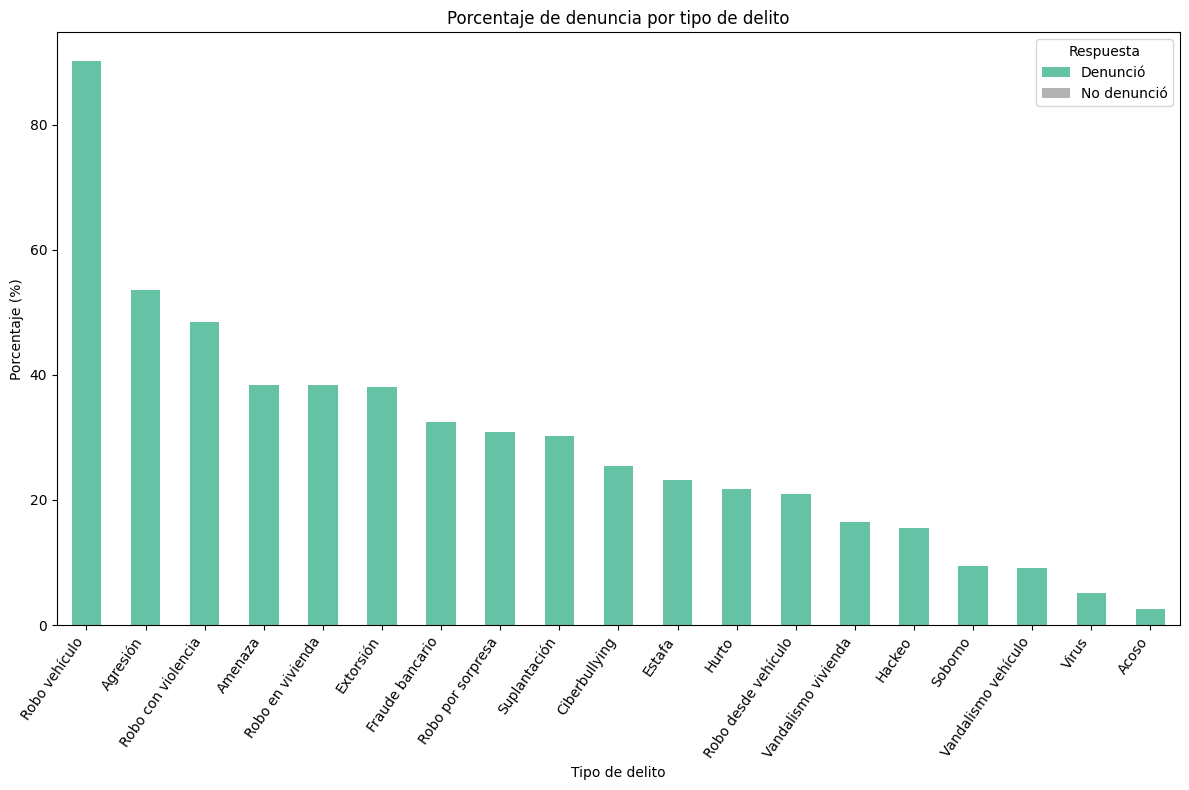

In [101]:
denuncias = [
    "ACOSO_DENUNCIA" if d == "VP_ACO" else f"{d}_DENUNCIAS"
    for d in delitos_consumados
]

data = []

for delito, denuncia, nombre in zip(delitos_consumados, denuncias, nombres_delitos):
    if delito in df_enusc.columns and denuncia in df_enusc.columns:
        victimas = df_enusc[df_enusc[delito] == 1]
        total = len(victimas)
        if total > 0:
            denuncio = (victimas[denuncia] == 1).sum()
            no_denuncio = (victimas[denuncia] == 0).sum()
            data.append({
                "Delito": nombre,
                "Denunció": denuncio / total * 100,
                "No denunció": no_denuncio / total * 100
            })

df_stack = pd.DataFrame(data).set_index("Delito")[["Denunció", "No denunció"]]
df_stack = df_stack.sort_values("Denunció", ascending=False)

df_stack.plot(kind="bar", stacked=True, figsize=(12, 8), colormap="Set2")
plt.title("Porcentaje de denuncia por tipo de delito")
plt.xlabel("Tipo de delito")
plt.ylabel("Porcentaje (%)")
plt.legend(title="Respuesta")
plt.xticks(rotation=55, ha='right')
plt.tight_layout()
plt.show()

Podemos ver que pese a que el acoso era el delito con mas frecuencia es el delito en el que menos se hacen las denuncias, esto sugiere que, aunque muchas personas lo sufren, existe una gran barrera para denunciarlo.

Podemos ver otra relacion inversa entre la frecuencia y la denuncia de algunos delitos, tales como Hurto, fraude bancario y vandalismo a vehiculos.

En cambio, delitos como robo de vehiculo o agresion muestran menos casos, pero una mayor proporción de denuncias, lo que puede indicar una mayor claridad legal o urgencia al momento de enfrentarlos.

Podemos apreciar ademas que los delitos con consecuencias más visibles o materiales(como el robo de un vehiculo) tienen tasas de denuncia mucho mayores.

Delitos como suplantación, ciberbullying o virus aunque afectan significativamente parecen tener una baja visibilidad legal o personal, lo que puede explicar la menor denuncia.


> **Nota (revisión posterior):** en la ENUSC la respuesta «No» de las variables de denuncia se codifica como 2, pero el código cuenta «No denunció» con el valor 0. Por eso esa parte de las barras queda vacía. El porcentaje de «Denunció» sí es correcto: por ejemplo, 2,5 % en acoso, 15,5 % en hackeo y 90,3 % en robo de vehículo.

### **5) Analisis Relacional**

### ¿Las fuentes de informacion influyen en la percepcion de inseguridad?

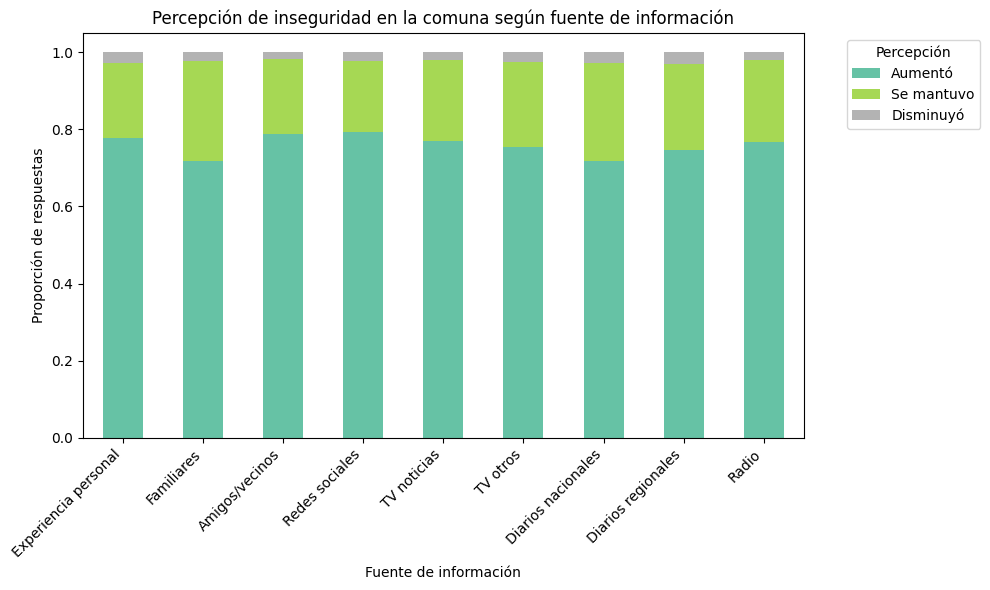

In [102]:
df_filtrado = df_enusc[
    df_enusc["P_FUENTE_INFO_COM_1"].between(1, 9) &
    df_enusc["P_AUMENTO_COM"].between(1, 3)
]


tabla = pd.crosstab(
    df_filtrado["P_FUENTE_INFO_COM_1"],
    df_filtrado["P_AUMENTO_COM"],
    normalize='index'  
)

tabla.columns = ["Aumentó", "Se mantuvo", "Disminuyó"]

fuentes = {
    1: "Experiencia personal",
    2: "Familiares",
    3: "Amigos/vecinos",
    4: "Redes sociales",
    5: "TV noticias",
    6: "TV otros",
    7: "Diarios nacionales",
    8: "Diarios regionales",
    9: "Radio"
}
tabla.index = tabla.index.map(fuentes)

tabla.plot(kind='bar', stacked=True, figsize=(10,6), colormap='Set2')
plt.title("Percepción de inseguridad en la comuna según fuente de información")
plt.ylabel("Proporción de respuestas")
plt.xlabel("Fuente de información")
plt.legend(title="Percepción", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Las personas que se informan principalmente por redes sociales o televisión tienden a reportar más frecuentemente que la delincuencia en su comuna aumentó, mientras que quienes se basan en la experiencia personal u otras fuentes más directas presentan una percepción algo más equilibrada.
Esto indica que la fuente de información influye significativamente en la construcción del temor, y que los medios masivos pueden reforzar percepciones más alarmistas.

> **Nota (revisión posterior):** las diferencias entre fuentes son pequeñas: cerca del 78-79 % de quienes se informan por redes sociales, amigos o vecinos o su experiencia personal cree que la delincuencia aumentó en su comuna, frente a cerca del 72 % de quienes se informan por familiares o diarios nacionales. La fuente influye, pero no explica por sí sola la percepción.

### ¿El nivel socioeconómico influye en la percepción de inseguridad?

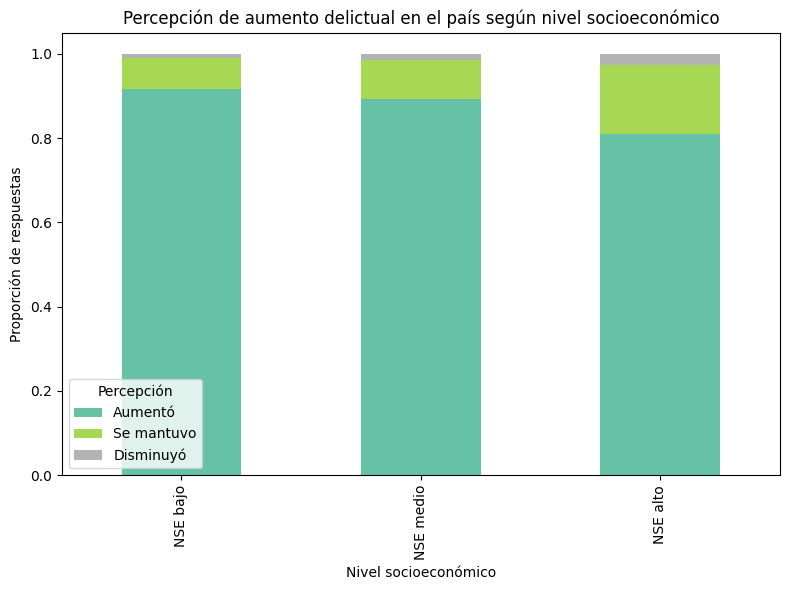

In [103]:

df_nse = df_enusc[
    df_enusc["rph_nse"].between(1, 3) &
    df_enusc["P_AUMENTO_PAIS"].between(1, 3)
]

tabla = pd.crosstab(
    df_nse["rph_nse"],
    df_nse["P_AUMENTO_PAIS"],
    normalize='index'
)

tabla.columns = ["Aumentó", "Se mantuvo", "Disminuyó"]
tabla.index = ["NSE bajo", "NSE medio", "NSE alto"]

tabla.plot(kind="bar", stacked=True, colormap="Set2", figsize=(8,6))
plt.title("Percepción de aumento delictual en el país según nivel socioeconómico")
plt.xlabel("Nivel socioeconómico")
plt.ylabel("Proporción de respuestas")
plt.legend(title="Percepción")
plt.tight_layout()
plt.show()
plt.show()

Las personas de nivel socioeconómico bajo perciben en mayor proporción que la delincuencia en el país ha aumentado, en comparación con los grupos de NSE medio y alto.
Esto sugiere que la percepción de inseguridad está vinculada a la posición social, y puede reflejar una experiencia más constante de vulnerabilidad o exposición a factores de riesgo.

### **6) Percepcion de inseguridad vs Victimizacion Real**

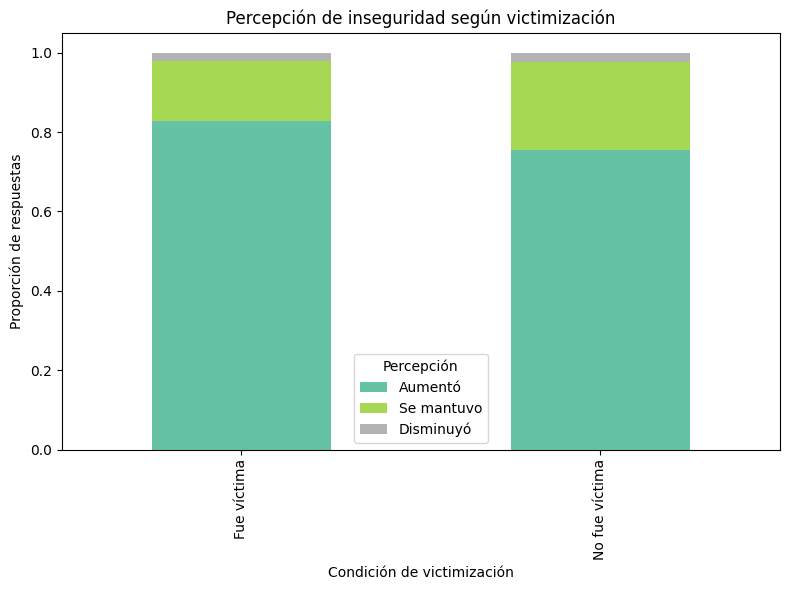

In [104]:

delitos = [
    "RDV", "RDDV", "RFV", "VANDVHC", "VANDVIV", "RVI", "RPS",
    "HUR", "FRB", "EST", "AGR", "AMEN", "EXT", "SOB", "HACK", "VIRUS", "BULLY", "SUPLANT"
]

df_enusc["TOTAL_DELITOS"] = df_enusc[delitos].apply(lambda row: (row == 1).sum(), axis=1)# victima o no

df_enusc["victima_bin"] = df_enusc["TOTAL_DELITOS"].apply(lambda x: 1 if x > 0 else 0)

df_victima = df_enusc[
    df_enusc["P_AUMENTO_COM"].isin([1, 2, 3])
][["victima_bin", "P_AUMENTO_COM"]].copy()

df_victima["percepcion"] = df_victima["P_AUMENTO_COM"].replace({
    1: "Aumentó",
    2: "Se mantuvo",
    3: "Disminuyó"
})


df_victima["victima"] = df_victima["victima_bin"].replace({
    0: "No fue víctima",
    1: "Fue víctima"
})

tabla = pd.crosstab(
    df_victima["victima"],
    df_victima["percepcion"],
    normalize='index'
)

tabla = tabla[["Aumentó", "Se mantuvo", "Disminuyó"]]

tabla.plot(kind="bar", stacked=True, figsize=(8,6), colormap="Set2")
plt.title("Percepción de inseguridad según victimización")
plt.xlabel("Condición de victimización")
plt.ylabel("Proporción de respuestas")
plt.legend(title="Percepción")
plt.tight_layout()
plt.show()


Se puede ver que la percepción de inseguridad de las víctimas de algún delito y quienes no lo han sido. Si bien se observa una ligera diferencia, donde las personas victimizadas tienden a declarar en mayor proporción que la delincuencia ha aumentado, esta brecha no es muy amplia. Esto sugiere que, aunque la experiencia directa influye en la percepción, no es el único factor determinante

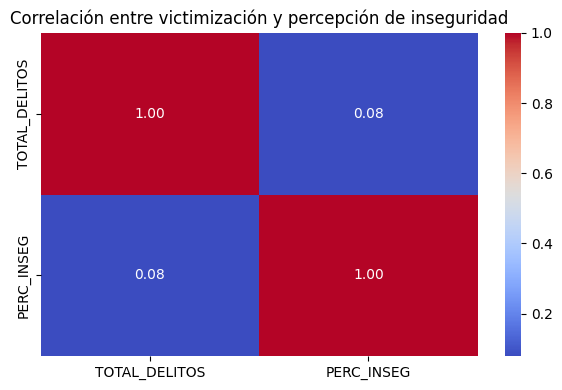

In [105]:
df_enusc["PERC_INSEG"] = df_enusc["P_AUMENTO_COM"].replace({
    1: 3,  
    2: 2,  
    3: 1,  
    88: pd.NA,
    99: pd.NA
})

df_corr = df_enusc[["TOTAL_DELITOS", "PERC_INSEG"]].dropna()
df_corr = df_corr.astype({"TOTAL_DELITOS": "float", "PERC_INSEG": "float"})

correlacion = df_corr.corr()

#heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación entre victimización y percepción de inseguridad")
plt.tight_layout()
plt.show()


Obtuvimos Correlación baja de 0.08 esto indica que el número de delitos sufridos apenas se relaciona con sentir que la inseguridad aumentó.
Asi la percepción de inseguridad no está completamente explicada por la experiencia directa a ser victima de algun delito.

Existen otros factores más relevantes que influyen en cómo las personas se sienten respecto a la seguridad, como podrian ser medios de comunicación, entorno social, edad, género, entre otros.

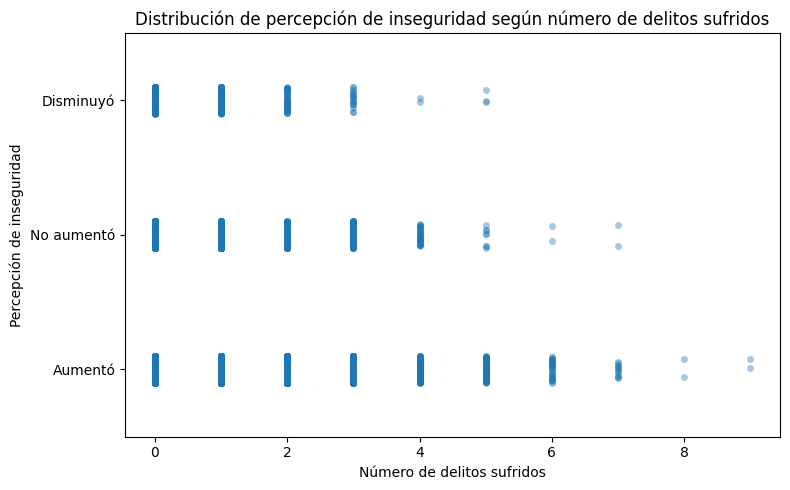

In [106]:

df_corr_plot = df_corr.copy()
df_corr_plot["PERC_INSEG_CAT"] = df_corr_plot["PERC_INSEG"].map({
    1.0: "Disminuyó",
    2.0: "No aumentó",
    3.0: "Aumentó"
})

plt.figure(figsize=(8, 5))
sns.stripplot(
    data=df_corr_plot,
    x="TOTAL_DELITOS",
    y="PERC_INSEG_CAT",
    alpha=0.4,
    jitter=True,
    order=["Disminuyó", "No aumentó", "Aumentó"]
)
plt.title("Distribución de percepción de inseguridad según número de delitos sufridos")
plt.xlabel("Número de delitos sufridos")
plt.ylabel("Percepción de inseguridad")
plt.tight_layout()
plt.show()

El gráfico de dispersión nos permite ver en detalle cómo se distribuyen las percepciones individuales en función del número de delitos sufridos. 
Se puede apreciar que incluso entre personas que no han sido víctimas, hay muchas que perciben un aumento de la delincuencia. Esto nos refuerza la idea de que la percepcion de inseguridad no es solo producto de la experiencia directa, sino que también está influida por otros factores, como el entorno social, los discursos mediáticos o las condiciones del territorio.


### **7) ¿Por que es importante la percepcion de inseguridad?**

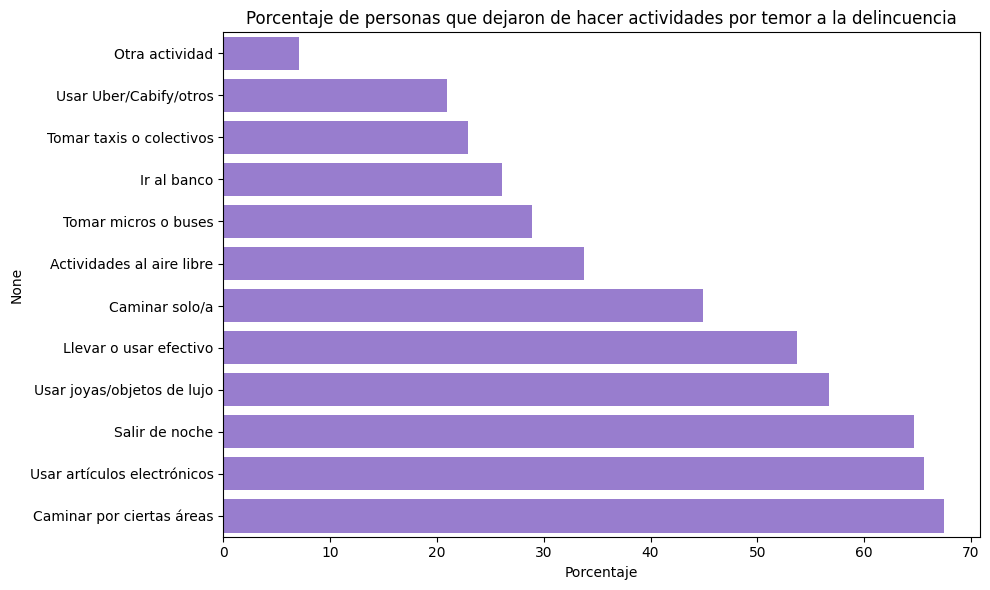

In [107]:
actividades = {
    "P_MOD_ACTIVIDADES_1": "Caminar solo/a",
    "P_MOD_ACTIVIDADES_2": "Actividades al aire libre",
    "P_MOD_ACTIVIDADES_3": "Usar artículos electrónicos",
    "P_MOD_ACTIVIDADES_4": "Tomar micros o buses",
    "P_MOD_ACTIVIDADES_5": "Tomar taxis o colectivos",
    "P_MOD_ACTIVIDADES_6": "Usar Uber/Cabify/otros",
    "P_MOD_ACTIVIDADES_7": "Caminar por ciertas áreas",
    "P_MOD_ACTIVIDADES_8": "Salir de noche",
    "P_MOD_ACTIVIDADES_9": "Usar joyas/objetos de lujo",
    "P_MOD_ACTIVIDADES_10": "Ir al banco",
    "P_MOD_ACTIVIDADES_11": "Llevar o usar efectivo",
    "P_MOD_ACTIVIDADES_12": "Otra actividad"
}

df_temor = df_enusc[list(actividades.keys())].copy()
df_temor = df_temor.replace([85, 88, 99], pd.NA).dropna()

porcentajes = (df_temor == 1).mean() * 100
porcentajes.index = [actividades[col] for col in porcentajes.index]
porcentajes = porcentajes.sort_values()

plt.figure(figsize=(10, 6))
sns.barplot(x=porcentajes.values, y=porcentajes.index, color="mediumpurple")
plt.xlabel("Porcentaje")
plt.title("Porcentaje de personas que dejaron de hacer actividades por temor a la delincuencia")
plt.tight_layout()
plt.show()

Como podemos apreciar la percepcion de inseguridad influye directamente en el dia de las personas, pues muchas dejan de hacer diversas actividades por temor a ser victimas de algun delito.